In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'image8/Butterfly.jpg' 

img = cv2.imread(imgFile)
if img is None:
    raise FileNotFoundError(f"Could not load '{imgFile}'. Check the name and folder.")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
print('Image shape:', img.shape)

Image shape: (532, 800, 3)


## Task 1: Edge Detection Methods

In [9]:
sobelx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
sobel_final = np.uint8(np.clip(cv2.magnitude(sobelx, sobely), 0, 255))

In [10]:
kernel_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64)
kernel_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float64)

prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)
prewitt_final = np.uint8(np.clip(cv2.magnitude(prewitt_x, prewitt_y), 0, 255))

In [12]:
canny_edges = cv2.Canny(blurred, 100, 200)

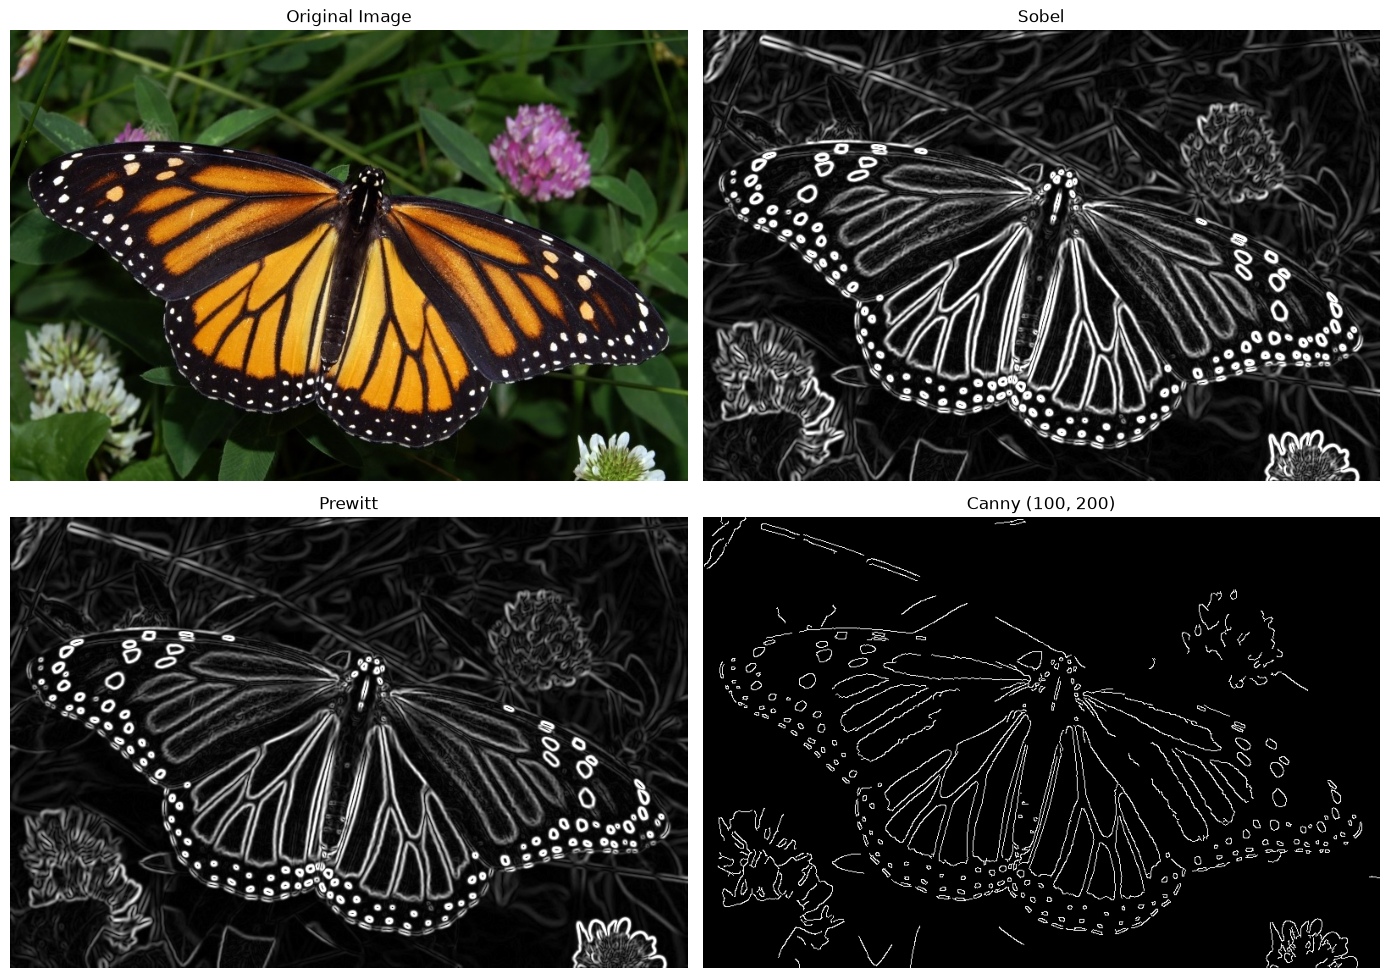

In [13]:
plt.figure(figsize=(14, 10))
plt.subplot(2, 2, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Original Image'), plt.axis('off')
plt.subplot(2, 2, 2), plt.imshow(sobel_final, cmap='gray'), plt.title('Sobel'), plt.axis('off')
plt.subplot(2, 2, 3), plt.imshow(prewitt_final, cmap='gray'), plt.title('Prewitt'), plt.axis('off')
plt.subplot(2, 2, 4), plt.imshow(canny_edges, cmap='gray'), plt.title('Canny (100, 200)'), plt.axis('off')
plt.tight_layout()
plt.show()

## Task 2: Effect of Canny Thresholds

Low=30, High=90 -> edge pixels: 33792
Low=50, High=150 -> edge pixels: 23434
Low=100, High=200 -> edge pixels: 16823


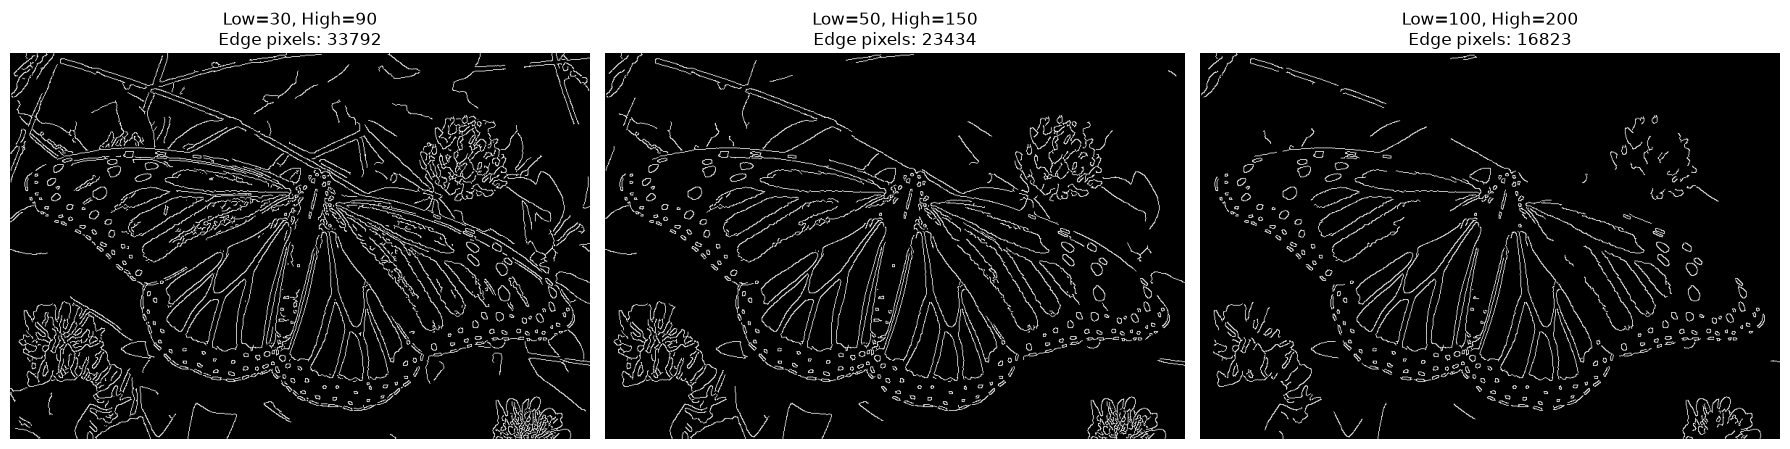

In [14]:
thresholds = [(30, 90), (50, 150), (100, 200)]

plt.figure(figsize=(18, 6))
for i, (low, high) in enumerate(thresholds, start=1):
    edges = cv2.Canny(blurred, low, high)
    count = np.count_nonzero(edges)
    plt.subplot(1, 3, i)
    plt.imshow(edges, cmap='gray')
    plt.title(f'Low={low}, High={high}\nEdge pixels: {count}')
    plt.axis('off')
    print(f'Low={low}, High={high} -> edge pixels: {count}')
plt.tight_layout()
plt.show()

### Explanation
Canny uses two thresholds. Pixels with a gradient above the **high** threshold are strong edges and are always kept. Pixels between **low** and **high** are kept only if they connect to a strong edge. Pixels below **low** are discarded.

- **Low = 30, High = 90:** Lowest thresholds, so the most edges are detected. Fine details and texture show up, but so does noise, and the map looks cluttered.
- **Low = 50, High = 150:** A balanced result. The main object boundaries and a reasonable amount of detail are kept, with less noise.
- **Low = 100, High = 200:** Highest thresholds, so the fewest edges are detected. Only strong, clear boundaries remain. Weak edges and fine details disappear, and some real edges may be broken.

**Conclusion:** Lower thresholds give more edges and more detail but also more noise. Higher thresholds give fewer, cleaner edges but lose detail.